In [2]:
import glob
import xarray as xr
import pandas as pd
import matplotlib as mpl

import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from aostools.climate import PlotEPfluxArrows

time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)

import numpy as np

def calculate_djf_mean(ds):
    ds_seasons = ds.resample(time='QE-FEB').mean()
    ds_djf = ds_seasons.sel(time=(ds_seasons['time.season'] == 'DJF'))
    ds_djf['time'] = pd.date_range(str(ds_djf.time[0].values).split('-')[0], str(int(str(ds_djf.time[-1].values).split('-')[0]) +1), freq='YS-FEB',unit='s')
    return ds_djf


def anomaly_calculation(model, clim):
    ano_list = []
    for i in range(1,13):
        ano_list.append(model.sel(time=model.time[model.time.dt.month.isin(i)]) - clim.sel(month=i))
    return xr.concat(ano_list, dim='time').sortby('time')


def load_climatology(path):
    clim = xr.open_dataset(glob.glob(path)[0])
    clim['time'] = [1,2,3,4,5,6,7,8,9,10,11,12]
    clim = clim.rename({'time': 'month'})
    return clim

def load_data(path):
    ens = []
    ds = []
    for p in glob.glob(path):
        ens.append(p.split('/')[-1].split('_')[4])
        ds.append(xr.open_dataset(p))
    data = xr.concat(ds, dim='ens')
    data['ens'] = ens

    return data

In [3]:
path = "/sto4/data/Intermediate/VolMIP/pinatubo-full/"
path_piControl = "/sto4/data/Intermediate/VolMIP/piControl/"
models = ['CanESM5', 'GISS-E2-1-G']
plotdir = '/home/kperny/VolMIP_stratosphere/plots/epflux/'
model = models[1]

enso_nao_flags = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/nao_enso_flags.csv')
enso_nao_flags = enso_nao_flags.set_index(['model', 'realization'])

In [4]:
path = "/sto4/data/Intermediate/VolMIP/pinatubo-full/"
path_piControl = "/sto4/data/Intermediate/VolMIP/piControl/"
models = ['CanESM5', 'GISS-E2-1-G']
plotdir = '/home/kperny/VolMIP_stratosphere/plots/epflux/'
model = models[0]

enso_nao_flags = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/nao_enso_flags.csv')
enso_nao_flags = enso_nao_flags.set_index(['model', 'realization'])
enso_nao_flags = enso_nao_flags.loc[model]

##### PICONTROL #####
epfz_clim_pi = load_climatology(path_piControl + model + '/epfz_clim_EmonZ*')
epfy_clim_pi = load_climatology(path_piControl + model + '/epfy_clim_EmonZ*')
utend_clim_pi = load_climatology(path_piControl + model + '/utendepfd_clim_EmonZ*')

epfz_tmp = xr.open_dataset(glob.glob(path_piControl + model + '/epfz_EmonZ*.nc')[0], decode_times=time_coder)
epfz_ano = anomaly_calculation(epfz_tmp, epfz_clim_pi)
epfz_piControl = calculate_djf_mean(epfz_ano)
# epfz_piControl = calculate_djf_mean(epfz_tmp)

epfy_tmp = xr.open_dataset(glob.glob(path_piControl + model + '/epfy_EmonZ*.nc')[0], decode_times=time_coder)
epfy_ano = anomaly_calculation(epfy_tmp, epfy_clim_pi)
epfy_piControl = calculate_djf_mean(epfy_ano)
# epfy_piControl = calculate_djf_mean(epfy_tmp)

utend_tmp = xr.open_dataset(glob.glob(path_piControl + model + '/utendepfd_EmonZ*.nc')[0], decode_times=time_coder)
utend_ano = anomaly_calculation(utend_tmp, utend_clim_pi)
utend_piControl = calculate_djf_mean(utend_ano)

utend_piControl['plev'] = utend_piControl['plev'] / 100 # utend_clim_pi.sel(plev=slice(100000,100)
epfz_piControl['plev'] = epfz_piControl['plev'] / 100 # epfz_piControl.sel(plev=slice(100000,100))
epfy_piControl['plev'] = epfy_piControl['plev'] / 100 # epfy_piControl.sel(plev=slice(100000,100))

##### VOLCANO #####
volc_nao_flags = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/nao_change.csv')
volc_nao_flags = volc_nao_flags.set_index(['model', 'realization'])
df_volc = volc_nao_flags.where(volc_nao_flags.experiment=='volc').dropna().drop('experiment', axis=1)
df_volc = df_volc.loc[model]

epfz_volc = load_data(path + model + '/epfz_EmonZ_*fixed_dates.nc')
epfy_volc = load_data(path + model + '/epfy_EmonZ_*fixed_dates.nc')
utend_volc = load_data(path + model + '/utendepfd_EmonZ_*fixed_dates.nc')

epfz_ano = anomaly_calculation(epfz_volc['epfz'], epfz_clim_pi['epfz'])
epfz_volc = calculate_djf_mean(epfz_ano)
# epfz_volc = calculate_djf_mean(epfz_volc.epfz)

epfy_ano = anomaly_calculation(epfy_volc['epfy'], epfy_clim_pi['epfy'])
epfy_volc = calculate_djf_mean(epfy_ano)
# epfy_volc = calculate_djf_mean(epfy_volc.epfy)

utend_ano = anomaly_calculation(utend_volc['utendepfd'], utend_clim_pi['utendepfd'])
utend_volc = calculate_djf_mean(utend_ano)

epfz_volc['plev'] = epfz_volc['plev'] / 100 # epfz_volc.sel(plev=slice(100000,100))
epfy_volc['plev'] = epfy_volc['plev'] / 100 # epfy_volc.sel(plev=slice(100000,100))
utend_volc['plev'] = utend_volc['plev'] / 100 # utend_volc.sel(plev=slice(100000,100))

/tmp/ipykernel_3238512/2313850707.py:30: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  clim = xr.open_dataset(glob.glob(path)[0])
/tmp/ipykernel_3238512/2313850707.py:30: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  clim = xr.open_dataset(glob.glob(path)[0])
/tmp/ipykernel_3238512/2313850707.py:30: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  clim = xr.o

In [21]:
epfy_piControl = epfy_piControl.sel(plev=slice(200,1), lat = slice(0,90))
epfz_piControl = epfz_piControl.sel(plev=slice(200,1), lat = slice(0,90))
utend_piControl = utend_piControl.sel(plev=slice(200,1), lat = slice(0,90))

epfy_volc = epfy_volc.sel(plev=slice(200,1), lat = slice(0,90))
epfz_volc = epfz_volc.sel(plev=slice(200,1), lat = slice(0,90))
utend_volc = utend_volc.sel(plev=slice(200,1), lat = slice(0,90))

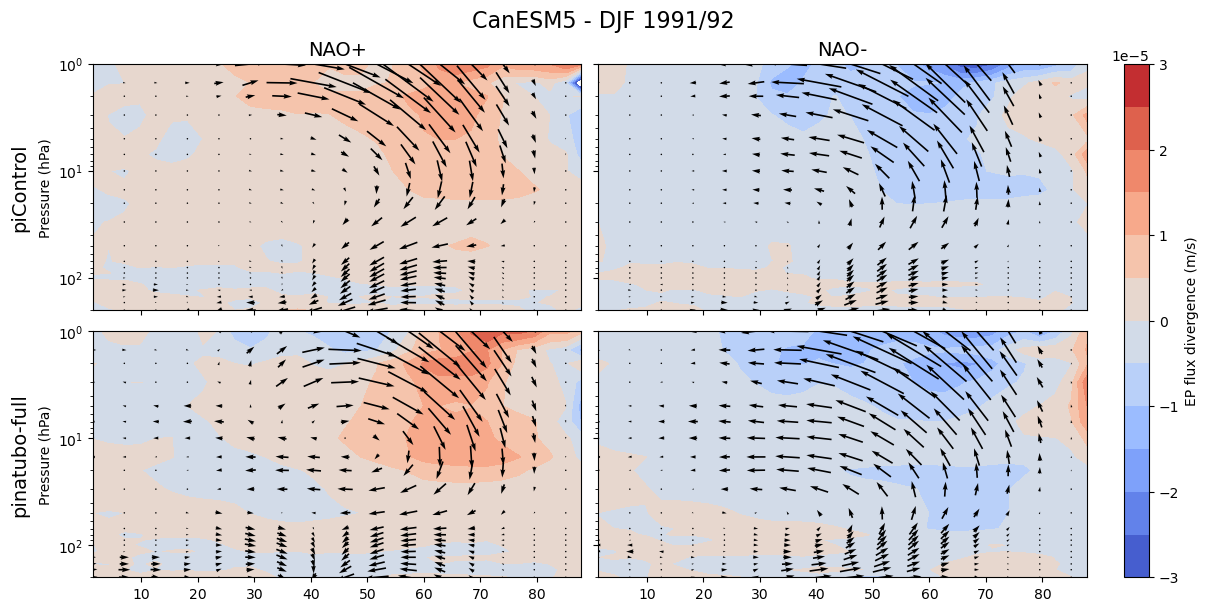

In [66]:
fig, axs = plt.subplots(2,2, figsize=(12,6), sharey=True, sharex=True, layout='constrained')

epfy = epfy_piControl.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag == 1).dropna().year.values).mean('time').epfy
epfz = epfz_piControl.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag == 1).dropna().year.values).mean('time').epfz
utend = utend_piControl.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag == 1).dropna().year.values).mean('time').utendepfd

c = axs[0,0].contourf(utend.lat, utend.plev, utend.values, cmap='coolwarm', levels=np.linspace(-3,3,13)*1e-5)
axs[0,0].quiver(epfy.lat[::2], epfy.plev, epfy[:,::2], epfz[:,::2]*100,  scale=1e9, pivot='mid')

epfy = epfy_piControl.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag == -1).dropna().year.values).mean('time').epfy
epfz = epfz_piControl.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag == -1).dropna().year.values).mean('time').epfz
utend = utend_piControl.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag == -1).dropna().year.values).mean('time').utendepfd

c2 = axs[0,1].contourf(utend.lat, utend.plev, utend.values, cmap='coolwarm', levels=np.linspace(-3,3,13)*1e-5)
axs[0,1].quiver(epfy.lat[::2], epfy.plev, epfy[:,::2], epfz[:,::2]*100,  scale=1e9, pivot='mid')


epfy = epfy_volc.sel(ens=df_volc.where(df_volc.nao_flag==1).dropna().index).sel(time='1992-02').mean('ens').squeeze()
epfz = epfz_volc.sel(ens=df_volc.where(df_volc.nao_flag==1).dropna().index).sel(time='1992-02').mean('ens').squeeze()
utend = utend_volc.sel(ens=df_volc.where(df_volc.nao_flag==1).dropna().index).sel(time='1992-02').mean('ens').squeeze()

c = axs[1,0].contourf(utend.lat, utend.plev, utend.values, cmap='coolwarm', levels=np.linspace(-3,3,13)*1e-5)
axs[1,0].quiver(epfy.lat[::2], epfy.plev, epfy[:,::2], epfz[:,::2]*100,  scale=1e9, pivot='mid')

epfy = epfy_volc.sel(ens=df_volc.where(df_volc.nao_flag==-1).dropna().index).sel(time='1992-02').mean('ens').squeeze()
epfz = epfz_volc.sel(ens=df_volc.where(df_volc.nao_flag==-1).dropna().index).sel(time='1992-02').mean('ens').squeeze()
utend = utend_volc.sel(ens=df_volc.where(df_volc.nao_flag==-1).dropna().index).sel(time='1992-02').mean('ens').squeeze()

c2 = axs[1,1].contourf(utend.lat, utend.plev, utend.values, cmap='coolwarm', levels=np.linspace(-3,3,13)*1e-5)
axs[1,1].quiver(epfy.lat[::2], epfy.plev, epfy[:,::2], epfz[:,::2]*100,  scale=1e9, pivot='mid')

axs[0,0].set_ylim(200,1)
axs[0,0].set_yscale('log')
axs[0,0].set_title('NAO+', fontsize=14)
axs[0,1].set_title('NAO-', fontsize=14)
axs[0,0].set_ylabel('Pressure (hPa)')
axs[1,0].set_ylabel('Pressure (hPa)')
axs[0,0].text(-0.15, 0.5, 'piControl', rotation=90, va='center', ha='center', transform=axs[0,0].transAxes, fontsize=14)
axs[1,0].text(-0.15, 0.5, 'pinatubo-full', rotation=90, va='center', ha='center', transform=axs[1,0].transAxes, fontsize=14)
fig.colorbar(c, ax=axs[0:2,1], orientation='vertical', label='EP flux divergence (m/s)')
fig.suptitle(model + ' - DJF 1991/92', fontsize=16)
plt.savefig(plotdir + 'epflux-div_' + model + 'djf199192.png', dpi=200)

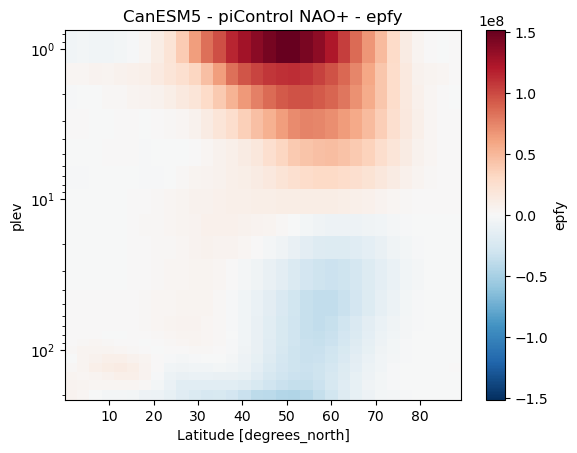

In [11]:
tmpy = epfy_piControl.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag == 1).dropna().year.values).sel(plev=slice(200,1), lat = slice(0,90)).mean('time').epfy#.plot(yincrease=False)#.sel(plev=slice(100000,1000), month=1).epfy.plot()
(tmpy).plot(yincrease=False)
plt.yscale('log')
plt.title(model + ' - piControl NAO+ - epfy')
plt.savefig(plotdir + 'epfy_piControl-naop_' + model + '.png', dpi=200)

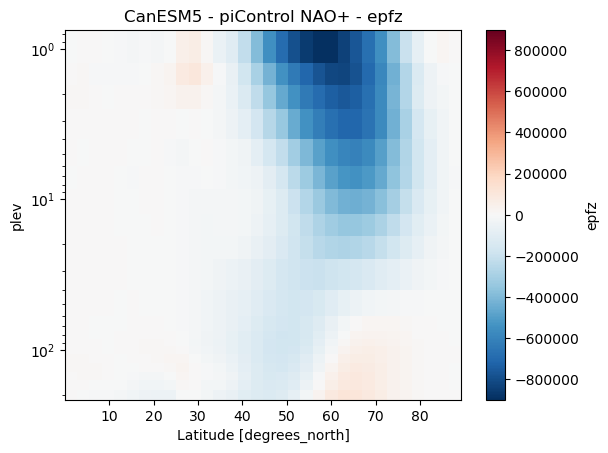

In [12]:
tmpz = epfz_piControl.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag == 1).dropna().year.values).sel(plev=slice(200,1), lat=slice(0,90)).mean('time').epfz
(tmpz).plot(yincrease=False)
plt.yscale('log')
plt.title(model + ' - piControl NAO+ - epfz')
plt.savefig(plotdir + 'epfz_piControl-naop_' + model + '.png', dpi=200)

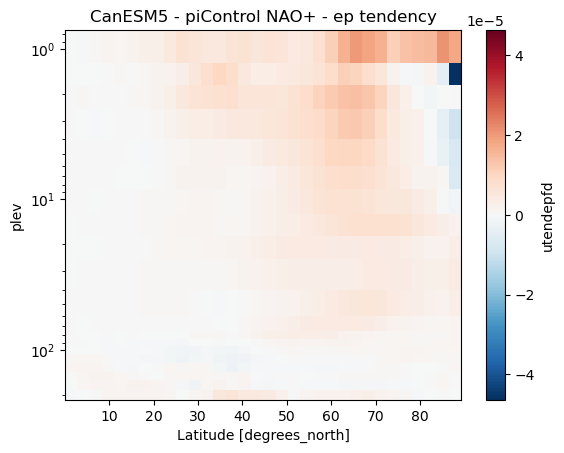

In [13]:
temputend = utend_piControl.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag == 1).dropna().year.values).sel(plev=slice(200,1), lat=slice(0,90)).mean('time').utendepfd
(temputend).plot(yincrease=False)
plt.yscale('log')
plt.title(model + ' - piControl NAO+ - ep tendency')
plt.savefig(plotdir + 'utend_piControl-naop_' + model + '.png', dpi=200)

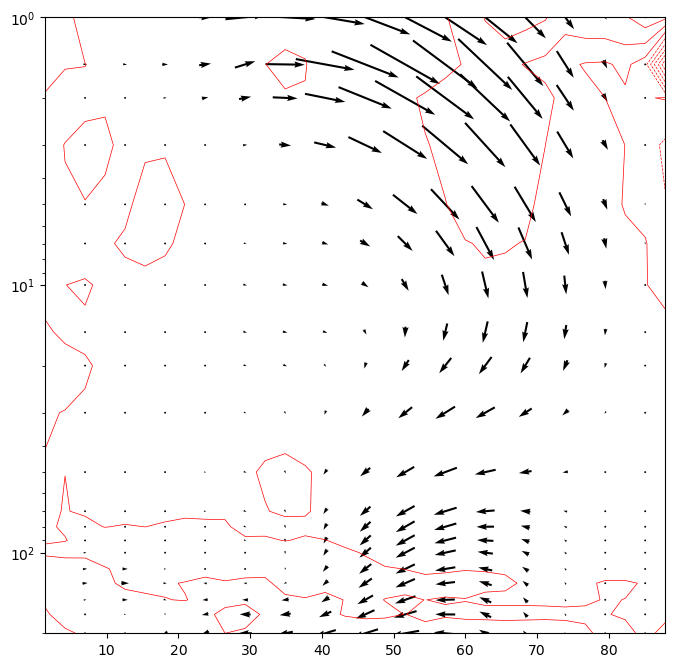

In [8]:
fig, axs = plt.subplots(1,1,figsize=(8,8))
axs.quiver(tmpy.lat[::2], tmpy.plev, tmpy[:,::2], tmpz[:,::2]*100,  scale=1e9, pivot='mid')
axs.contour(temputend.lat, temputend.plev, temputend.values, levels=8, colors='red', linewidths=0.5)
plt.ylim(200,1)
plt.yscale('log')

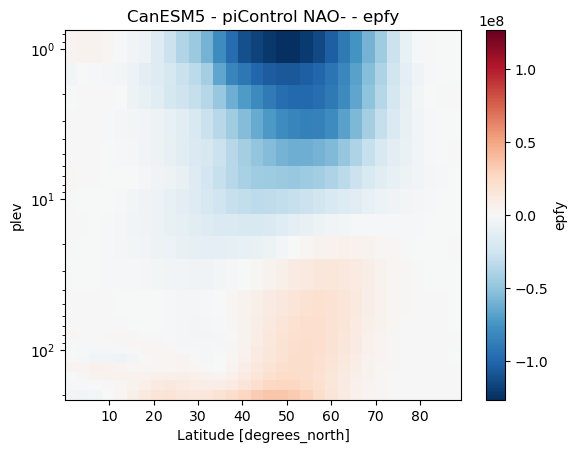

In [10]:
tmpy = epfy_piControl.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag == -1).dropna().year.values).sel(plev=slice(200,1), lat = slice(0,90)).mean('time').epfy#.plot(yincrease=False)#.sel(plev=slice(100000,1000), month=1).epfy.plot()
(tmpy).plot(yincrease=False)
plt.yscale('log')
plt.title(model + ' - piControl NAO- - epfy')
plt.savefig(plotdir + 'epfy_piControl-naon_' + model + '.png', dpi=200)


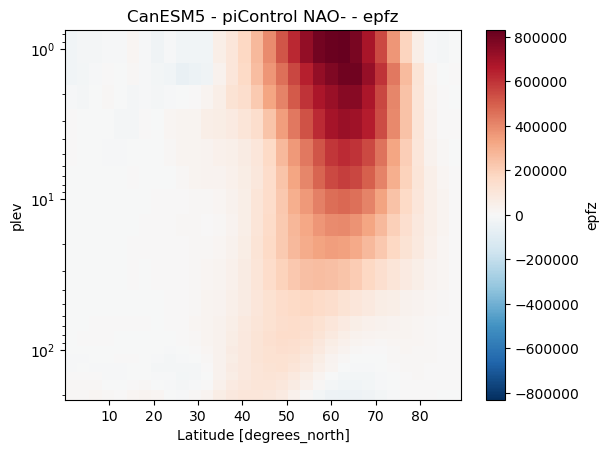

In [15]:
tmpz = epfz_piControl.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag == -1).dropna().year.values).sel(plev=slice(200,1), lat=slice(0,90)).mean('time').epfz
(tmpz).plot(yincrease=False)
plt.yscale('log')
plt.title(model + ' - piControl NAO- - epfz')
plt.savefig(plotdir + 'epfz_piControl-naon_' + model + '.png', dpi=200)

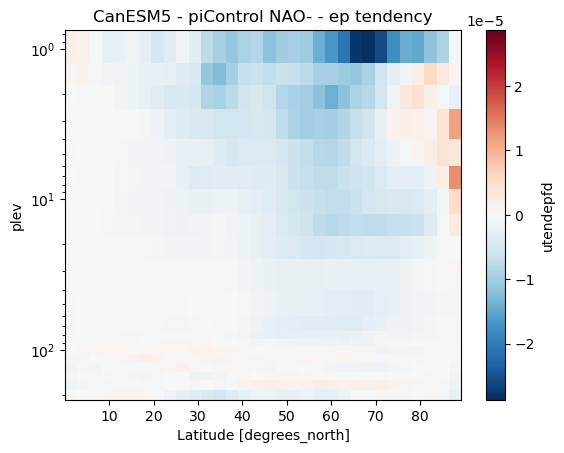

In [16]:
temputend = utend_piControl.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag == -1).dropna().year.values).sel(plev=slice(200,1), lat=slice(0,90)).mean('time').utendepfd
(temputend).plot(yincrease=False)
plt.yscale('log')
plt.title(model + ' - piControl NAO- - ep tendency')
plt.savefig(plotdir + 'utend_piControl-naon_' + model + '.png', dpi=200)

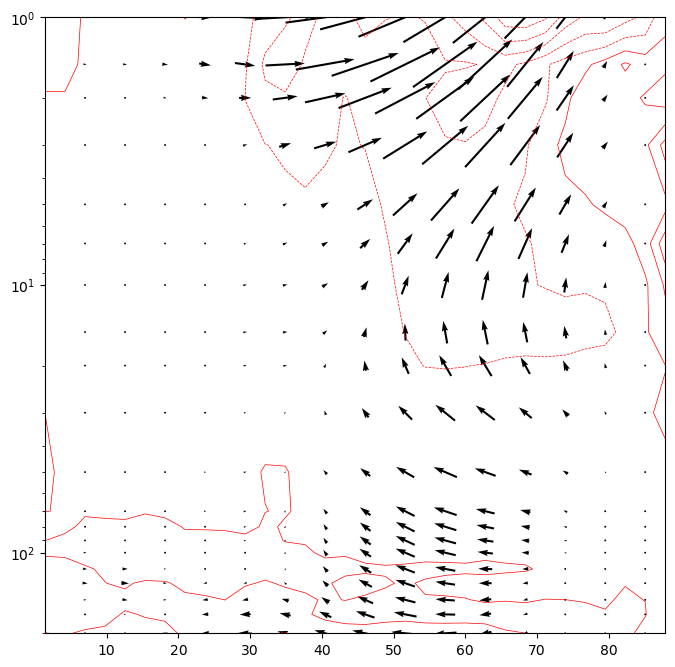

In [17]:
fig, axs = plt.subplots(1,1,figsize=(8,8))
axs.quiver(tmpy.lat[::2], tmpy.plev, tmpy[:,::2], tmpz[:,::2]*100,  scale=1e9, pivot='mid')
axs.contour(temputend.lat, temputend.plev, temputend.values, levels=8, colors='red', linewidths=0.5)
plt.ylim(200,1)
plt.yscale('log')

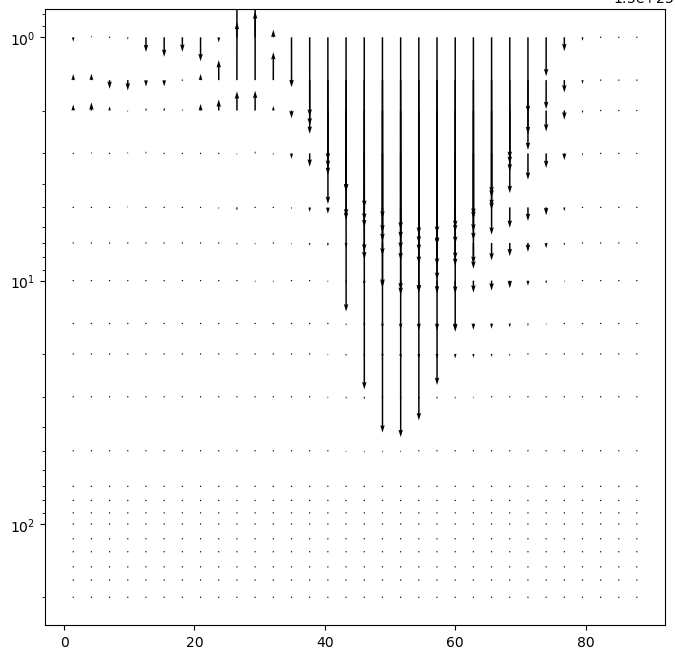

In [31]:
fig, axs = plt.subplots(1,1,figsize=(8,8))
plev = slice(300,1)
lat = slice(0,90)
naopz = epfz_piControl.epfz.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag == 1).dropna().year.values).sel(plev=slice(200,1), lat=slice(0,90)).mean('time')
naopy = epfy_piControl.epfy.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag == 1).dropna().year.values).sel(plev=slice(200,1), lat=slice(0,90)).mean('time')
Fphi,Fp = PlotEPfluxArrows(naopy.lat, naopy.plev, naopy, naopz*-1, fig=fig, ax=axs, xlim=None, ylim=None, xscale='linear', yscale='log', invert_y=True)
#axs.yaxis.set_major_formatter(fmt)